In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler, PCA
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
import numpy as np

spark = SparkSession.builder \
    .master("local[*]") \
    .appName("RetailMart_Q6_PCA_Deployment") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

from google.colab import drive
drive.mount('/content/drive')

df = spark.read.parquet("/content/drive/MyDrive/cleaned_retailmart_master.parquet")
df = df.dropna(subset=["churn"]).withColumn(
    "churn_num", when(col("churn") == "Yes", 1.0).otherwise(0.0))

train, test = df.randomSplit([0.7, 0.3], seed=42)
print(f"Loaded: {df.count():,} rows | Train: {train.count():,} | Test: {test.count():,}")

Mounted at /content/drive
Loaded: 920,864 rows | Train: 644,696 | Test: 276,168


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/models/decision_tree_model"
best_model = PipelineModel.load(MODEL_PATH)

evaluator_f1  = MulticlassClassificationEvaluator(labelCol="churn_num", metricName="f1")
evaluator_acc = MulticlassClassificationEvaluator(labelCol="churn_num", metricName="accuracy")

baseline_pred = best_model.transform(test)
baseline_f1  = evaluator_f1.evaluate(baseline_pred)
baseline_acc = evaluator_acc.evaluate(baseline_pred)

print(f"Baseline (tuned DT) — F1: {baseline_f1:.4f} | Accuracy: {baseline_acc:.4f}")

# Reuse the fitted preprocessing stages (everything except the DT)
prep = PipelineModel(stages=best_model.stages[:-1])
train_p = prep.transform(train).cache()
test_p  = prep.transform(test).cache()
_ = train_p.count()

n_features = train_p.select("features").first()[0].size
print(f"Feature dimension after OHE: {n_features}")

Baseline (tuned DT) — F1: 0.7265 | Accuracy: 0.7833
Feature dimension after OHE: 55


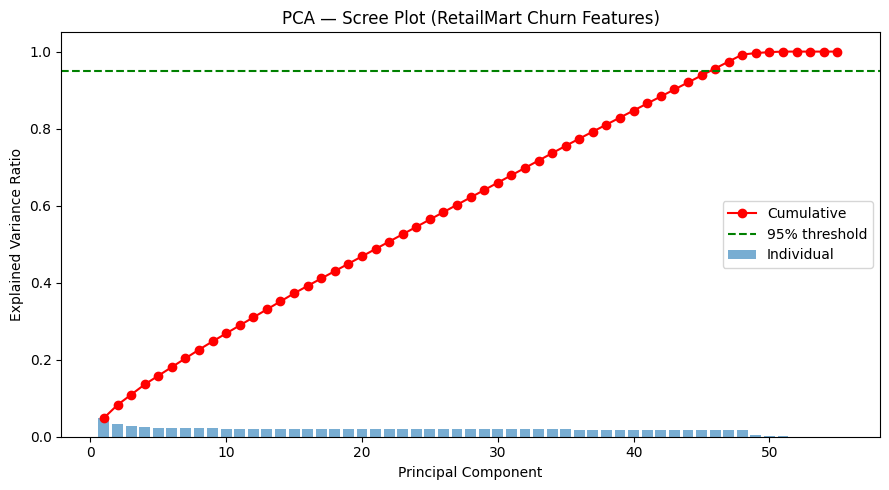

Components needed for 95% variance: 46 of 55
Dimensions reduced by: 16.4%


In [ ]:
# Fit full PCA (k = all features) so we can see the complete variance profile
pca_full = PCA(k=n_features, inputCol="features", outputCol="pca_full").fit(train_p)
explained  = pca_full.explainedVariance.toArray()
cumulative = np.cumsum(explained)

plt.figure(figsize=(9, 5))
plt.bar(range(1, n_features + 1), explained, alpha=0.6, label="Individual")
plt.plot(range(1, n_features + 1), cumulative, "r-o", label="Cumulative")
plt.axhline(0.95, color="green", linestyle="--", label="95% threshold")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA — Scree Plot (RetailMart Churn Features)")
plt.legend()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/retailmart_pca_scree.png", dpi=150)
plt.show()

k95 = int(np.argmax(cumulative >= 0.95) + 1)
print(f"Components needed for 95% variance: {k95} of {n_features}")
print(f"Dimensions reduced by: {(1 - k95/n_features)*100:.1f}%")

In [ ]:
# Reduce to k95 components
pca_k = PCA(k=k95, inputCol="features", outputCol="pca_features").fit(train_p)
train_pca = pca_k.transform(train_p).cache()
test_pca  = pca_k.transform(test_p).cache()
_ = train_pca.count()

dt_pca = DecisionTreeClassifier(
    labelCol="churn_num", featuresCol="pca_features",
    maxDepth=7, minInstancesPerNode=20, seed=42)

pca_pred = dt_pca.fit(train_pca).transform(test_pca)
pca_f1   = evaluator_f1.evaluate(pca_pred)
pca_acc  = evaluator_acc.evaluate(pca_pred)

print(f"DT + PCA ({k95} comps)  — F1: {pca_f1:.4f} | Accuracy: {pca_acc:.4f}")
print(f"DT + full ({n_features} feats) — F1: {baseline_f1:.4f} | Accuracy: {baseline_acc:.4f}")
print(f"Δ F1: {pca_f1 - baseline_f1:+.4f}")

DT + PCA (46 comps)  — F1: 0.7177 | Accuracy: 0.7821
DT + full (55 feats) — F1: 0.7265 | Accuracy: 0.7833
Δ F1: -0.0088


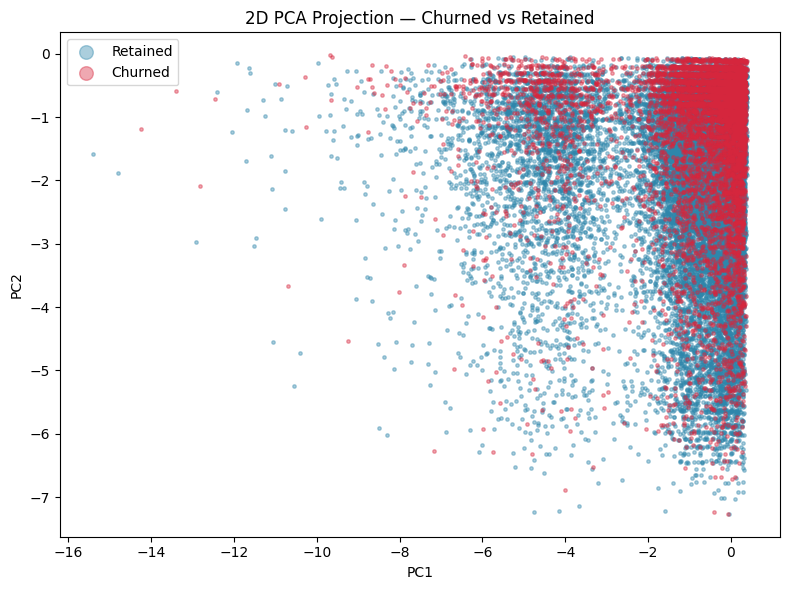

In [ ]:
pca_2d = PCA(k=2, inputCol="features", outputCol="pca2").fit(train_p)
sample = (
    pca_2d.transform(train_p)
    .select(vector_to_array("pca2").alias("pca2"), "churn_num")
    .sample(False, 0.05, seed=42)
    .toPandas()
)
sample["pc1"] = sample["pca2"].apply(lambda v: v[0])
sample["pc2"] = sample["pca2"].apply(lambda v: v[1])

plt.figure(figsize=(8, 6))
for label, color, name in [(0.0, "#2E86AB", "Retained"), (1.0, "#D7263D", "Churned")]:
    subset = sample[sample["churn_num"] == label]
    plt.scatter(subset["pc1"], subset["pc2"], s=6, alpha=0.4, c=color, label=name)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("2D PCA Projection — Churned vs Retained")
plt.legend(markerscale=4)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/retailmart_pca_2d.png", dpi=150)
plt.show()

In [ ]:
numeric_cols     = ["customer_age", "loyalty_years", "num_visits",
                    "unit_price", "quantity", "total_amount"]
categorical_cols = ["customer_gender", "product_category",
                    "payment_method", "store_location"]

indexers = [StringIndexer(inputCol=c, outputCol=c+"_idx", handleInvalid="keep")
            for c in categorical_cols]
encoders = [OneHotEncoder(inputCol=c+"_idx", outputCol=c+"_ohe")
            for c in categorical_cols]
assembler = VectorAssembler(
    inputCols=numeric_cols + [c+"_ohe" for c in categorical_cols],
    outputCol="raw_features")
scaler = StandardScaler(inputCol="raw_features", outputCol="features")
dt_final = DecisionTreeClassifier(
    labelCol="churn_num", featuresCol="features",
    maxDepth=7, minInstancesPerNode=20, seed=42)

production_pipeline = Pipeline(
    stages=indexers + encoders + [assembler, scaler, dt_final])

print("Fitting production pipeline on 100% of data...")
production_model = production_pipeline.fit(df)

PROD_PATH = "/content/drive/MyDrive/models/retailmart_churn_production_model"
production_model.write().overwrite().save(PROD_PATH)
print(f"Production model saved → {PROD_PATH}")
print("Note: honest performance estimate is the held-out F1 from Q4 = "
      f"{baseline_f1:.4f} (this full-data model is for deployment, not reporting).")

Fitting production pipeline on 100% of data...
Production model saved → /content/drive/MyDrive/models/retailmart_churn_production_model
Note: honest performance estimate is the held-out F1 from Q4 = 0.7265 (this full-data model is for deployment, not reporting).


In [ ]:
def score_customers(model, df_raw):
    """Take raw transaction records → return churn risk per customer."""
    scored = model.transform(df_raw)
    return scored.select(
        "customer_id",
        vector_to_array("probability")[1].alias("churn_probability"),
        F.col("prediction").cast("int").alias("churn_prediction")
    ).withColumn(
        "risk_band",
        F.when(F.col("churn_probability") >= 0.50, "HIGH")
         .when(F.col("churn_probability") >= 0.30, "MEDIUM")
         .otherwise("LOW")
    ).orderBy(F.desc("churn_probability"))

# Demo on 10 real records
score_customers(production_model, df.limit(10)).show(truncate=False)

+------------------------------------+-------------------+----------------+---------+
|customer_id                         |churn_probability  |churn_prediction|risk_band|
+------------------------------------+-------------------+----------------+---------+
|41499c9d-703a-4063-9914-da64546db904|0.4498475788486341 |0               |MEDIUM   |
|8a1b371b-a21a-4e18-9e40-839c08540c68|0.287627680443753  |0               |LOW      |
|178b4a0c-3490-4547-b7ea-67f62894f238|0.25050208558628145|0               |LOW      |
|94cc8159-f8d0-4cda-8125-89b8358c274f|0.20049467275494673|0               |LOW      |
|0116a57b-df33-430b-9b67-b91d850f5825|0.20049467275494673|0               |LOW      |
|48cf1f1a-0aad-458a-b479-50c95144dd52|0.19655354419986706|0               |LOW      |
|72269e95-767a-4158-9d95-d162917039b3|0.15191892110524308|0               |LOW      |
|782ba39b-6a56-4747-abb7-36cf56d36231|0.10322047206954243|0               |LOW      |
|0e838a07-bba9-4248-8862-e9d6b3ed23b3|0.10322047206954

In [ ]:
from pyspark.sql.functions import lit

# Take one real record, strip the target (production data won't have it)
new_customer = (
    df.drop("churn", "churn_num")
      .limit(1)
      .withColumn("churn", lit(None).cast("string"))
      .withColumn("churn_num", lit(0.0))
)

print("Fresh model load (simulating separate deployment environment)...")
fresh_model = PipelineModel.load(PROD_PATH)

result = score_customers(fresh_model, new_customer)
result.show(truncate=False)

Fresh model load (simulating separate deployment environment)...
+------------------------------------+-----------------+----------------+---------+
|customer_id                         |churn_probability|churn_prediction|risk_band|
+------------------------------------+-----------------+----------------+---------+
|8a1b371b-a21a-4e18-9e40-839c08540c68|0.287627680443753|0               |LOW      |
+------------------------------------+-----------------+----------------+---------+



In [ ]:
print(f"""
============================================================
RETAILMART CHURN MODEL — DEPLOYMENT CARD
============================================================
Artifact : {PROD_PATH}
Type     : PySpark PipelineModel
Stages   : 4x StringIndexer → 4x OneHotEncoder → VectorAssembler
           → StandardScaler → DecisionTreeClassifier

INPUTS
  Numeric     : {", ".join(numeric_cols)}
  Categorical : {", ".join(categorical_cols)}

OUTPUTS
  churn_probability (0-1) | churn_prediction (0/1) | risk_band (LOW/MEDIUM/HIGH)

PERFORMANCE (held-out test, same hyperparameters)
  F1 = {baseline_f1:.4f}  |  Accuracy = {baseline_acc:.4f}
  Recall ≈ 0.13 — flags only the highest-confidence churners.

LIMITATIONS
  - Low recall: use for prioritisation, not automated adverse action.
  - Gender features dominate — audit before causal use.
  - PCA tested ({k95} comps): F1 = {pca_f1:.4f} — full features retained.
============================================================
""")


RETAILMART CHURN MODEL — DEPLOYMENT CARD
Artifact : /content/drive/MyDrive/models/retailmart_churn_production_model
Type     : PySpark PipelineModel
Stages   : 4x StringIndexer → 4x OneHotEncoder → VectorAssembler
           → StandardScaler → DecisionTreeClassifier

INPUTS
  Numeric     : customer_age, loyalty_years, num_visits, unit_price, quantity, total_amount
  Categorical : customer_gender, product_category, payment_method, store_location

OUTPUTS
  churn_probability (0-1) | churn_prediction (0/1) | risk_band (LOW/MEDIUM/HIGH)

PERFORMANCE (held-out test, same hyperparameters)
  F1 = 0.7265  |  Accuracy = 0.7833
  Recall ≈ 0.13 — flags only the highest-confidence churners.

LIMITATIONS
  - Low recall: use for prioritisation, not automated adverse action.
  - Gender features dominate — audit before causal use.
  - PCA tested (46 comps): F1 = 0.7177 — full features retained.

